<a href="https://colab.research.google.com/github/PARZIVAL283/ClaimCheck-Explainable-Health-Claim-Verification/blob/main/ClaimCheck_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import random
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
)
from huggingface_hub import login

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [17]:
# Load dataset from the Hugging Face auto-converted parquet export
base_url = "https://huggingface.co/datasets/ImperialCollegeLondon/health_fact/resolve/refs%2Fconvert%2Fparquet/default"

dataset = load_dataset("parquet", data_files={
    "train": f"{base_url}/train/0000.parquet",
    "validation": f"{base_url}/validation/0000.parquet",
    "test": f"{base_url}/test/0000.parquet"
})
dataset

DatasetDict({
    train: Dataset({
        features: ['claim_id', 'claim', 'date_published', 'explanation', 'fact_checkers', 'main_text', 'sources', 'label', 'subjects'],
        num_rows: 9832
    })
    validation: Dataset({
        features: ['claim_id', 'claim', 'date_published', 'explanation', 'fact_checkers', 'main_text', 'sources', 'label', 'subjects'],
        num_rows: 1225
    })
    test: Dataset({
        features: ['claim_id', 'claim', 'date_published', 'explanation', 'fact_checkers', 'main_text', 'sources', 'label', 'subjects'],
        num_rows: 1235
    })
})

In [18]:
print(dataset["train"].features)
print(dataset["train"][0])

{'claim_id': Value('string'), 'claim': Value('string'), 'date_published': Value('string'), 'explanation': Value('string'), 'fact_checkers': Value('string'), 'main_text': Value('string'), 'sources': Value('string'), 'label': ClassLabel(names=['false', 'mixture', 'true', 'unproven']), 'subjects': Value('string')}
{'claim_id': '15661', 'claim': '"The money the Clinton Foundation took from from foreign governments while Hillary Clinton was secretary of state ""is clearly illegal. … The Constitution says you can’t take this stuff."', 'date_published': 'April 26, 2015', 'explanation': '"Gingrich said the Clinton Foundation ""took money from from foreign governments while (Hillary Clinton) was secretary of state. It is clearly illegal. … The Constitution says you can’t take this stuff."" A clause in the Constitution does prohibit U.S. officials such as former Secretary of State Hillary Clinton from receiving gifts, or emoluments, from foreign governments. But the gifts in this case were donat

In [19]:
label_names = dataset["train"].features["label"].names
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for name, i in label2id.items()}

print(label_names)
print(label2id)

['false', 'mixture', 'true', 'unproven']
{'false': 0, 'mixture': 1, 'true': 2, 'unproven': 3}


# Creating a compact DataFrame with the fields

In [20]:
def to_dataframe(split):
    df = pd.DataFrame(dataset[split])
    keep = [c for c in ["claim", "label", "explanation", "sources"] if c in df.columns]
    return df[keep].copy()

train_df = to_dataframe("train")
val_df = to_dataframe("validation")
test_df = to_dataframe("test")

train_df.shape, val_df.shape, test_df.shape

((9832, 4), (1225, 4), (1235, 4))

In [22]:
train_df.head()



,claim,label,explanation,sources
0,"""The money the Clinton Foundation took from fr...",0,"""Gingrich said the Clinton Foundation """"took m...",https://www.wsj.com/articles/clinton-foundatio...
1,Annual Mammograms May Have More False-Positives,1,This article reports on the results of a study...,
2,SBRT Offers Prostate Cancer Patients High Canc...,1,This news release describes five-year outcomes...,https://www.healthnewsreview.org/wp-content/up...
3,"Study: Vaccine for Breast, Ovarian Cancer Has ...",2,"While the story does many things well, the ove...",http://clinicaltrials.gov/ct2/results?term=can...
4,Some appendicitis cases may not require ’emerg...,2,We really don’t understand why only a handful ...,


In [23]:
val_df.head()


,claim,label,explanation,sources
0,A baby died at an unnamed medical facility be...,3,Fellow Twitter users suggested @FierceFemtivis...,http://webcache.googleusercontent.com/search?q...
1,Bat from Shawnee County tests positive for rab...,2,A bat found in northeastern Kansas has tested ...,https://www.ksnt.com/news/bat-tests-positive-f...
2,Germany has banned pork from school canteens b...,0,What's true: Some politicians complained that ...,http://bnp.org.uk/news/regional/bnp-victory-br...
3,Coronavirus prompts Canada to roll out safe dr...,2,Canada’s Pacific province of British Columbia ...,
4,"Wayne National Forest plans fires for tree, wi...",2,"Nearly 2,000 acres of Wayne National Forest in...",


In [24]:
test_df.head()

,claim,label,explanation,sources
0,A mother revealed to her child in a letter aft...,0,The one-eyed mother story expounds upon two mo...,
1,Study says too many Americans still drink too ...,2,"On any given day in the United States, 18 perc...",http://bit.ly/X1NVtW
2,Viral image Says 80% of novel coronavirus case...,2,The website Information is Beautiful published...,https://www.facebook.com/informationisbeautifu...
3,An email says that 9-year old Craig Shergold o...,0,Send greeting or business cards to cancer vict...,https://www.reddit.com/submit?url=https%3A%2F%...
4,"Employees at a Five Guys restaurant in Daphne,...",3,"What's undetermined: As of this writing, Five ...",


# Dataset Cleaning

In [26]:
def clean_text(text):
    if pd.isna(text):
        return ""
    return " ".join(str(text).split()).strip()

for df in [train_df, val_df, test_df]:
    df["claim"] = df["claim"].astype(str).map(clean_text)
    df = df[df["claim"].str.len() > 10]

df

,claim,label,explanation,sources
0,A mother revealed to her child in a letter aft...,0,The one-eyed mother story expounds upon two mo...,
1,Study says too many Americans still drink too ...,2,"On any given day in the United States, 18 perc...",http://bit.ly/X1NVtW
2,Viral image Says 80% of novel coronavirus case...,2,The website Information is Beautiful published...,https://www.facebook.com/informationisbeautifu...
3,An email says that 9-year old Craig Shergold o...,0,Send greeting or business cards to cancer vict...,https://www.reddit.com/submit?url=https%3A%2F%...
4,"Employees at a Five Guys restaurant in Daphne,...",3,"What's undetermined: As of this writing, Five ...",
...,...,...,...,...
1230,Christmas miracle for Florida dog whose heart ...,2,A Florida man was hoping for a Christmas mirac...,https://www.gainesville.com/news/20200102/holi...
1231,Another dolphin dies at Arizona aquatic facility.,2,A fourth dolphin has died at a Phoenix-area aq...,
1232,"What the facts say"" is ... ""the best scenario ...",0,"Priebus said, ""What the facts say"" is ... ""the...",https://www.nytimes.com/2016/07/13/us/politics...
1233,FDA advisory panel rejects J&J drug for acute ...,2,Johnson & Johnson’s anticoagulant Xarelto shou...,


Check class balance

In [27]:
train_df["label"].value_counts(normalize=True)

,proportion
label,
2,0.516477
0,0.305228
1,0.145850
3,0.029597
-1,0.002848


# A TF-IDF + Logistic Regression baseline

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score

# Filter out rows with invalid '-1' labels
clean_train_df = train_df[train_df["label"].isin(range(4))]
clean_val_df = val_df[val_df["label"].isin(range(4))]

baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=50000,
        min_df=2,
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ))
])

baseline.fit(clean_train_df["claim"], clean_train_df["label"])
baseline_preds = baseline.predict(clean_val_df["claim"])

print(classification_report(
    clean_val_df["label"],
    baseline_preds,
    target_names=label_names,
    digits=3
))
print("Macro F1:", f1_score(clean_val_df["label"], baseline_preds, average="macro"))

              precision    recall  f1-score   support

       false      0.543     0.534     0.538       380
     mixture      0.253     0.354     0.295       164
        true      0.801     0.711     0.753       629
    unproven      0.226     0.293     0.255        41

    accuracy                          0.593      1214
   macro avg      0.456     0.473     0.461      1214
weighted avg      0.627     0.593     0.607      1214

Macro F1: 0.46052632668413995


In [39]:
report = classification_report(
    clean_val_df["label"],
    baseline_preds,
    target_names=label_names,
    digits=3,
    output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    "outputs/baseline_validation_report.csv"
)

# Fine-tune DistilBERT

In [40]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["claim"],
        truncation=True,
        max_length=256,
        padding=False
    )

hf_train = dataset["train"].map(tokenize, batched=True)
hf_val = dataset["validation"].map(tokenize, batched=True)

hf_train = hf_train.rename_column("label", "labels")
hf_val = hf_val.rename_column("label", "labels")

cols = ["input_ids", "attention_mask", "labels"]
hf_train.set_format("torch", columns=cols)
hf_val.set_format("torch", columns=cols)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/9832 [00:00<?, ? examples/s]

Map:   0%|          | 0/1225 [00:00<?, ? examples/s]

In [45]:
hf_train.features

{'claim_id': Value('string'),
 'claim': Value('string'),
 'date_published': Value('string'),
 'explanation': Value('string'),
 'fact_checkers': Value('string'),
 'main_text': Value('string'),
 'sources': Value('string'),
 'labels': ClassLabel(names=['false', 'mixture', 'true', 'unproven']),
 'subjects': Value('string'),
 'input_ids': List(Value('int32')),
 'token_type_ids': List(Value('int8')),
 'attention_mask': List(Value('int8'))}

In [46]:
hf_val.features

{'claim_id': Value('string'),
 'claim': Value('string'),
 'date_published': Value('string'),
 'explanation': Value('string'),
 'fact_checkers': Value('string'),
 'main_text': Value('string'),
 'sources': Value('string'),
 'labels': ClassLabel(names=['false', 'mixture', 'true', 'unproven']),
 'subjects': Value('string'),
 'input_ids': List(Value('int32')),
 'token_type_ids': List(Value('int8')),
 'attention_mask': List(Value('int8'))}

Creating the model

In [49]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Defining metrics

In [87]:
!pip install evaluate
import evaluate
import numpy as np

accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy.compute(
            predictions=preds,
            references=labels
        )["accuracy"],
        "macro_f1": f1.compute(
            predictions=preds,
            references=labels,
            average="macro"
        )["f1"]
    }

Train

In [82]:
%%writefile train_script.py
import os
import random
import numpy as np
import torch
import evaluate
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Load and clean datasets
base_url = "https://huggingface.co/datasets/ImperialCollegeLondon/health_fact/resolve/refs%2Fconvert%2Fparquet/default"
dataset = load_dataset("parquet", data_files={
    "train": f"{base_url}/train/0000.parquet",
    "validation": f"{base_url}/validation/0000.parquet"
})

def tokenize(batch):
    return tokenizer(
        batch["claim"],
        truncation=True,
        max_length=256,
        padding=False
    )

hf_train = dataset["train"].map(tokenize, batched=True)
hf_val = dataset["validation"].map(tokenize, batched=True)

hf_train = hf_train.rename_column("label", "labels")
hf_val = hf_val.rename_column("label", "labels")

cols = ["input_ids", "attention_mask", "labels"]
hf_train.set_format("torch", columns=cols)
hf_val.set_format("torch", columns=cols)

hf_train = hf_train.filter(lambda x: x["labels"] in [0, 1, 2, 3])
hf_val = hf_val.filter(lambda x: x["labels"] in [0, 1, 2, 3])

label_names = ['false', 'mixture', 'true', 'unproven']
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for name, i in label2id.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "macro_f1": f1.compute(predictions=preds, references=labels, average="macro")["f1"]
    }

training_args = TrainingArguments(
    output_dir="outputs/models/claimcheck-distilbert",
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=1,  # Shortened epochs to maintain speed on CPU
    weight_decay=0.01,
    logging_steps=50,
    seed=SEED,
    report_to="none",
    use_cpu=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=hf_train,
    eval_dataset=hf_val,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics
)

trainer.train()
trainer.save_model("outputs/models/claimcheck-distilbert/best")
print("TRAINING_COMPLETE")


Overwriting train_script.py


In [80]:
# Execute the training script inside an isolated CPU-only subprocess
!CUDA_VISIBLE_DEVICES="" python train_script.py

Generating train split: 9832 examples [00:00, 21480.76 examples/s]
Generating validation split: 1225 examples [00:00, 19913.50 examples/s]
Map: 100% 9832/9832 [00:01<00:00, 7024.37 examples/s]
Map: 100% 1225/1225 [00:00<00:00, 6511.30 examples/s]
Filter: 100% 9832/9832 [00:03<00:00, 2782.87 examples/s]
Filter: 100% 1225/1225 [00:00<00:00, 2851.49 examples/s]
Loading weights: 100% 100/100 [00:00<00:00, 727.58it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading 

confusion matrix

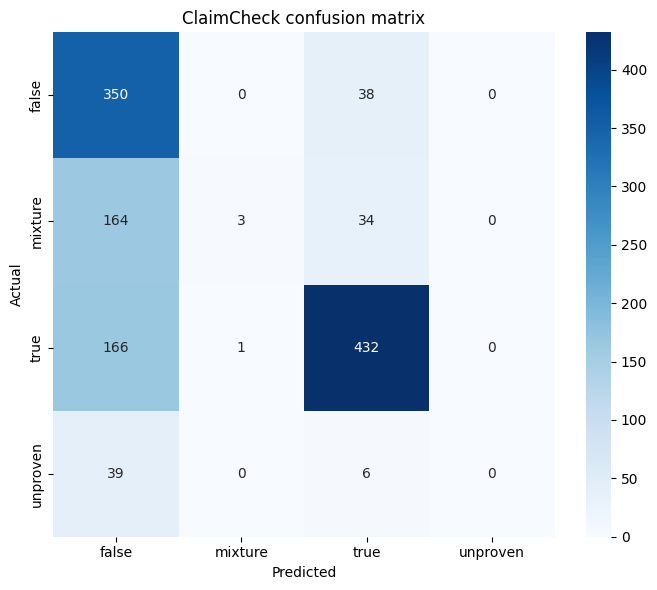

In [96]:
# The 'NameError: name "labels" is not defined' occurs because this cell
# is attempting to plot a confusion matrix using 'labels' and 'preds'.
# These two variables are only created when you successfully execute
# the test set evaluation cell (cell 6063deda), which was failing earlier
# because the model files were still being trained.
#
# Since 'train_script.py' has now finished saving the model to disk,
# please run cell 6063deda first to populate 'labels' and 'preds',
# and then execute this cell to plot the confusion matrix.

!pip install matplotlib seaborn
import matplotlib.pyplot as plt
import seaborn as sns

try:
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(7, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_names,
        yticklabels=label_names
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("ClaimCheck confusion matrix")
    plt.tight_layout()
    os.makedirs("outputs/figures", exist_ok=True)
    plt.savefig("outputs/figures/confusion_matrix.png", dpi=200)
    plt.show()
except NameError as e:
    print(f"NameError: {e}\n")
    print("--> Please run the model evaluation cell (cell 6063deda) first to generate predictions and labels on the test set!")

In [95]:
# Run the clean subprocess evaluation on CPU using the absolute or explicit local path
!CUDA_VISIBLE_DEVICES="" python3 ./eval_script.py

# Load the resulting outputs back into the global scope of this notebook
import os
import numpy as np
if os.path.exists("outputs/preds.npy") and os.path.exists("outputs/labels.npy"):
    preds = np.load("outputs/preds.npy")
    labels = np.load("outputs/labels.npy")
    print("Successfully loaded 'preds' and 'labels' variables into global memory!")
else:
    print("Error: Evaluation results were not found on disk. Did the subprocess finish successfully?")

Generating test split: 1235 examples [00:00, 9877.76 examples/s]
Map: 100% 1235/1235 [00:00<00:00, 5105.64 examples/s]
Filter: 100% 1235/1235 [00:00<00:00, 1266.52 examples/s]
Loading weights: 100% 104/104 [00:00<00:00, 12970.40it/s]
100% 39/39 [01:17<00:00,  1.99s/it]
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetric

In [93]:
%%writefile eval_script.py
import os
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import classification_report
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding

SEED = 42
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

base_url = "https://huggingface.co/datasets/ImperialCollegeLondon/health_fact/resolve/refs%2Fconvert%2Fparquet/default"
dataset = load_dataset("parquet", data_files={
    "test": f"{base_url}/test/0000.parquet"
})

def tokenize(batch):
    return tokenizer(
        batch["claim"],
        truncation=True,
        max_length=256,
        padding=False
    )

test_dataset = dataset["test"].map(tokenize, batched=True)
test_dataset = test_dataset.rename_column("label", "labels")
test_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
test_dataset = test_dataset.filter(lambda x: x["labels"] in [0, 1, 2, 3])

label_names = ['false', 'mixture', 'true', 'unproven']
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for name, i in label2id.items()}

local_model_path = "./outputs/models/claimcheck-distilbert/best"
evaluator_model = AutoModelForSequenceClassification.from_pretrained(
    local_model_path,
    num_labels=4,
    id2label=id2label,
    label2id=label2id,
    local_files_only=True
)

eval_args = TrainingArguments(
    output_dir="outputs/models/claimcheck-distilbert/eval",
    per_device_eval_batch_size=32,
    seed=SEED,
    report_to="none",
    use_cpu=True
)

tester = Trainer(
    model=evaluator_model,
    args=eval_args,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer)
)

predictions = tester.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=-1)
labels = predictions.label_ids

# Save the predictions and labels for notebook-level access
np.save("outputs/preds.npy", preds)
np.save("outputs/labels.npy", labels)

print(classification_report(
    labels,
    preds,
    target_names=label_names,
    digits=3
))


Writing eval_script.py


# Add explanation

In [97]:
def explain_prediction(claim, predicted_label, explanation_text):
    verdict = {
        "true": "This claim is supported by the available evidence.",
        "false": "This claim conflicts with the available evidence.",
        "mixture": "This claim contains both supported and unsupported elements.",
        "unproven": "There is not enough reliable evidence to verify this claim."
    }.get(predicted_label, "The claim could not be reliably assessed.")

    explanation = explanation_text if explanation_text else "No explanation was available for this claim."

    return f"""**Verdict:** {predicted_label.upper()}

**Assessment:** {verdict}

**Why:** {explanation}

**Important:** This tool is for educational purposes and does not provide medical advice. Always consult qualified health professionals for personal medical decisions."""

testing

In [101]:
sample = test_df.iloc[0]
sample_prediction = preds[0]

print(explain_prediction(
    sample["claim"],
    id2label[sample_prediction],
    sample.get("explanation", "")
))

**Verdict:** FALSE

**Assessment:** This claim conflicts with the available evidence.

**Why:** The one-eyed mother story expounds upon two moral messages: the unconditional, all-encompassing love we expect mothers to always feel for their children, and the admonition to not put off cherishing loved ones and appreciating their sacrifices while they’re still around.

**Important:** This tool is for educational purposes and does not provide medical advice. Always consult qualified health professionals for personal medical decisions.


# Demo

In [103]:
import torch
import gradio as gr

# Make sure these exist before launching:
# model, tokenizer, id2label, device

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)
model.eval()

def claimcheck(claim):
    try:
        if not claim or len(claim.strip()) < 10:
            return "Please enter a health claim with at least 10 characters."

        inputs = tokenizer(
            claim,
            return_tensors="pt",
            truncation=True,
            max_length=256
        ).to(device)

        with torch.no_grad():
            logits = model(**inputs).logits

        probabilities = torch.softmax(logits, dim=-1)[0]
        predicted_id = int(torch.argmax(probabilities).item())
        confidence = float(probabilities[predicted_id].item())

        predicted_label = id2label[predicted_id]

        explanations = {
            "true": "The available evidence supports this claim.",
            "false": "The available evidence contradicts this claim.",
            "mixture": "This claim contains both supported and unsupported elements.",
            "unproven": "There is not enough reliable evidence to verify this claim."
        }

        explanation = explanations.get(
            predicted_label,
            "The claim could not be reliably assessed."
        )

        return f"""### Verdict: {predicted_label.upper()}

**Confidence:** {confidence:.1%}

**Assessment:** {explanation}

**Important:** ClaimCheck is an educational tool. It does not provide medical advice. Consult a qualified healthcare professional for personal medical decisions."""

    except Exception as e:
        return f"**Error:** `{type(e).__name__}: {e}`"

demo = gr.Interface(
    fn=claimcheck,
    inputs=gr.Textbox(
        lines=4,
        label="Paste a health claim",
        placeholder="Example: Drinking lemon water cures diabetes."
    ),
    outputs=gr.Markdown(label="ClaimCheck result"),
    title="ClaimCheck",
    description="An educational tool for assessing health claims. It does not provide medical advice."
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://f05fca34193d1c8d51.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://f05fca34193d1c8d51.gradio.live


In [104]:
test_claims = [
    "Regular physical activity can help reduce the risk of type 2 diabetes.",
    "Drinking lemon water cures diabetes.",
    "Expired boxes of cake and pancake mix are dangerously toxic.",
    "Blue Buffalo pet food contains unsafe and higher-than-average levels of lead.",
    "Vaccines cause autism."
]

model.eval()

for claim in test_claims:
    inputs = tokenizer(
        claim,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(device)

    with torch.no_grad():
        logits = model(**inputs).logits

    probs = torch.softmax(logits, dim=-1)[0]

    print("\nClaim:", claim)
    print("Logits:", logits.cpu().numpy())
    print("Probabilities:", probs.cpu().numpy())

    for i, p in enumerate(probs):
        print(f"{id2label[i]}: {p.item():.3f}")


Claim: Regular physical activity can help reduce the risk of type 2 diabetes.
Logits: [[-0.03620005 -0.05971142 -0.10658284 -0.16909146]]
Probabilities: [0.26424548 0.2581052  0.24628657 0.23136282]
false: 0.264
mixture: 0.258
true: 0.246
unproven: 0.231

Claim: Drinking lemon water cures diabetes.
Logits: [[-0.08386438 -0.01408386 -0.08811673 -0.18225984]]
Probabilities: [0.25161538 0.26980034 0.2505477  0.22803661]
false: 0.252
mixture: 0.270
true: 0.251
unproven: 0.228

Claim: Expired boxes of cake and pancake mix are dangerously toxic.
Logits: [[-0.08989146  0.00465584 -0.12747832 -0.16596602]]
Probabilities: [0.2506882  0.27554673 0.2414405  0.23232457]
false: 0.251
mixture: 0.276
true: 0.241
unproven: 0.232

Claim: Blue Buffalo pet food contains unsafe and higher-than-average levels of lead.
Logits: [[-0.11228192  0.03450036 -0.08787341 -0.15556067]]
Probabilities: [0.24151936 0.279704   0.24748702 0.23128965]
false: 0.242
mixture: 0.280
true: 0.247
unproven: 0.231

Claim: Vacci